**PRAKTIKUM KECERDASAN BUATAN W09S02** <br>
Materi: Neural Network (Klasifikasi Gambar Alternatif) <br>
By: Gresia Delia Silalahi_42324011

In [5]:
%pip install numpy matplotlib tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.85.1-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached keras_nightly-3.16.0.dev2026110303-py3-none-any.whl.metadata (6.6 kB)
  Using cached h5py-3.15.1-cp314-cp314-win_amd64.whl.metadata (3.1 kB)
  Using cached ml_dtypes-0.6.0-cp314-cp314-win_amd64.whl.metadata (8.8 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


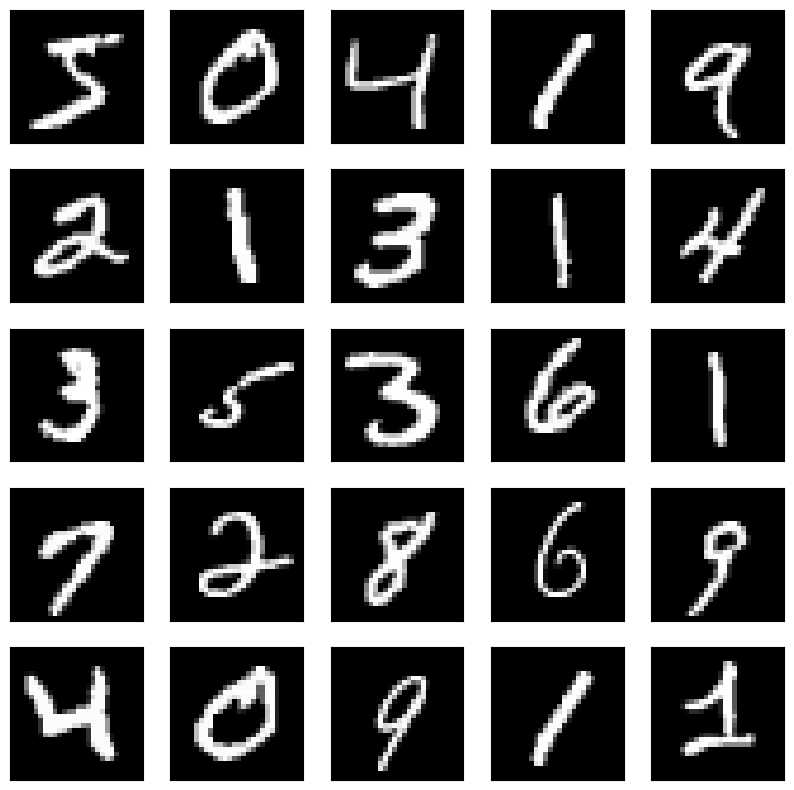

In [6]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images / 255.0
test_images = test_images / 255.0

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
plt.show()

In [7]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Flatten(input_shape=(28, 28)),  # Mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),  # Hidden layer dengan 128 neuron
    Dense(10, activation='softmax')  # Output layer dengan 10 neuron untuk klasifikasi 10 kategori
])

# Melihat ringkasan arsitektur model
model.summary()

c:\Users\ASUS\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Melatih model dengan data training
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9259 - loss: 0.2576 - val_accuracy: 0.9587 - val_loss: 0.1357
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9666 - loss: 0.1128 - val_accuracy: 0.9697 - val_loss: 0.0997
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9770 - loss: 0.0773 - val_accuracy: 0.9736 - val_loss: 0.0889
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9834 - loss: 0.0569 - val_accuracy: 0.9755 - val_loss: 0.0811
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9883 - loss: 0.0420 - val_accuracy: 0.9755 - val_loss: 0.0797
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9915 - loss: 0.0310 - val_accuracy: 0.9775 - val_loss: 0.0775
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9934 - loss: 0.0244 - val_accuracy: 0.9769 - val_loss: 0.0810
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9953 - loss: 0.0

In [9]:
# Evaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9794 - loss: 0.0879

Test accuracy: 0.9793999791145325


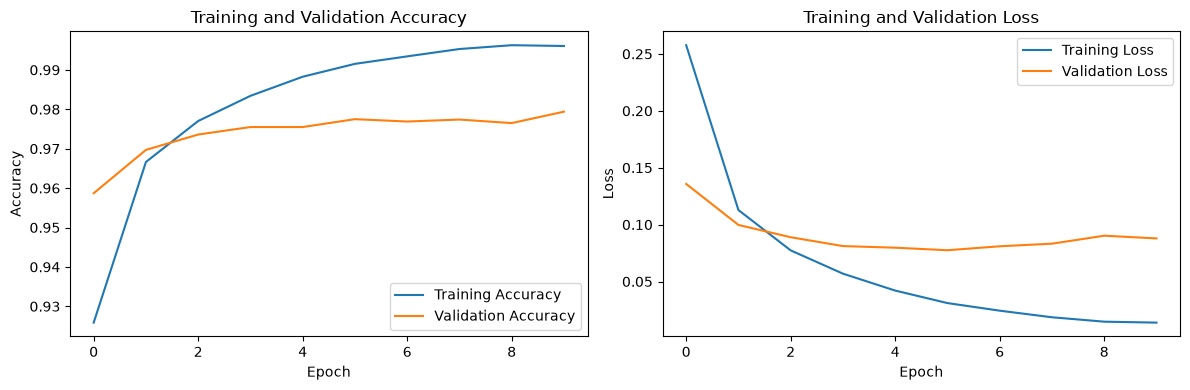

In [10]:
# Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


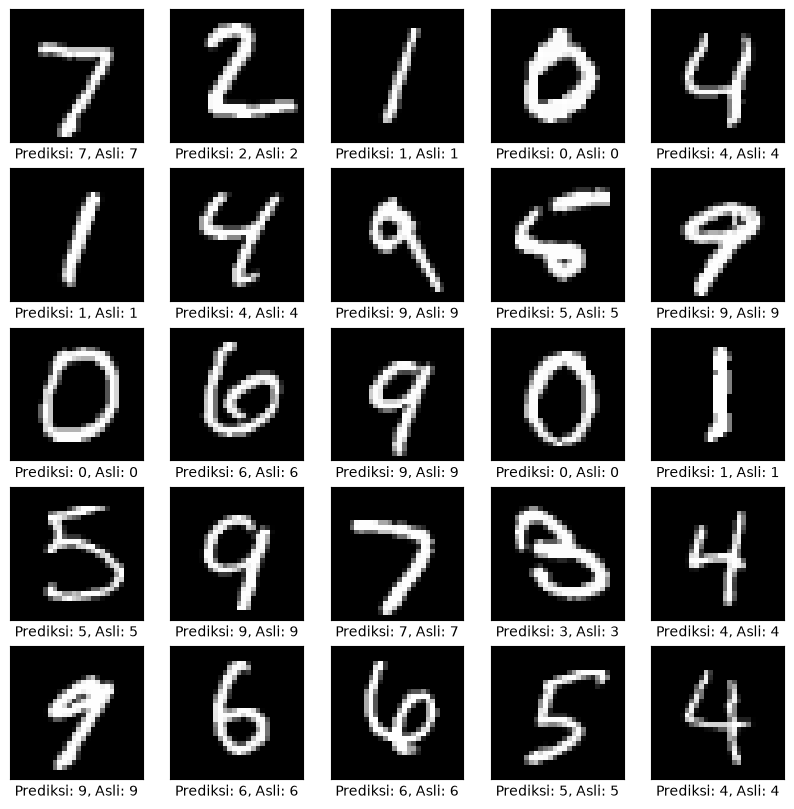

In [11]:
# Melakukan prediksi pada gambar pengujian
import numpy as np
predictions = model.predict(test_images)

# Contoh prediksi untuk 25 gambar pertama
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    plt.xlabel(f"Prediksi: {predicted_label}, Asli: {actual_label}")
plt.show()

Mengimplementasikan seluruh alur kode praktikum Neural Network pada dataset baru yaitu MNIST Handwritten Digits (angka tulisan tangan 0 sampai 9), menggantikan dataset pakaian (Fashion MNIST). Struktur sel, tahapan pra-pemrosesan, arsitektur model, dan fungsi evaluasi dibuat ekuivalen 100%.</br>
Pada MNIST Digits, angka tersusun atas goresan garis tunggal berlatar belakang hitam murni dengan sifat topologis yang sangat jelas (angka 0 berbentuk lingkaran utuh, angka 1 berbentuk garis lurus vertikal). Kombinasi linier pada 128 neuron ReLU dapat memisahkan batas keputusan antar-kelas dengan margin yang besar.